In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data=pd.read_csv("loan_approval_data.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

In [3]:
'str' in str(data['Marital_Status'].dtype)

True

In [4]:
#Pre Processing
for i in data.columns:
    if('int' in str(data[i].dtype) or 'float' in str(data[i].dtype)):
        data[i]=data[i].replace(np.nan,0)
    elif ('str' in str(data[i].dtype)):
        data[i]=data[i].replace(np.nan,'empty')


In [5]:
#Take 2 PreProcessing
for i in data.columns:
    if('int' in str(data[i].dtype) or 'float' in str(data[i].dtype)):
        data[i]=data[i].replace(0,data[i].mean())
    elif ('str' in str(data[i].dtype)):
        data[i]=data[i].replace('empty',data[i].mode()[0])

In [6]:
#data split
data_X=data.drop('Loan_Approved',axis=1)
data_y=data['Loan_Approved']

In [7]:
listing_str_columns=[]
for l in data_X.columns:
    if('str' in str(data[l].dtype)):
        listing_str_columns.append(l)

listing_str_columns

['Employment_Status',
 'Marital_Status',
 'Loan_Purpose',
 'Property_Area',
 'Education_Level',
 'Gender',
 'Employer_Category']

In [8]:
#One Hot Encoding
data_encoded_X=pd.get_dummies(data=data_X,columns=listing_str_columns,drop_first=True,dtype=int)

In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(data_encoded_X,data_y,test_size=0.23,random_state=23)


In [10]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
data_scaled_X_train=sc.fit_transform(X_train)
data_scaled_X_test=sc.transform(X_test)

<Axes: >

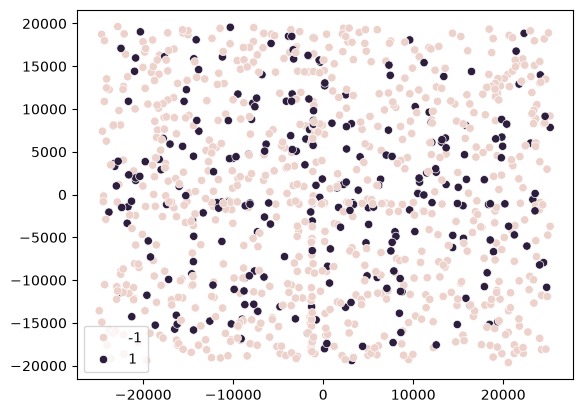

In [11]:
#Optional 
#checking outliers
from sklearn.ensemble import IsolationForest
ife=IsolationForest(n_estimators=237,random_state=23)
labels=ife.fit_predict(data_encoded_X)
#Visualising the data
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
data_2d=pca.fit_transform(data_encoded_X)
sns.scatterplot(x=data_2d[:,0],y=data_2d[:,1],hue=labels)

# EDA

In [12]:
axrow=0
axcol=0
for col in data.columns:
    if(str(data[col].dtype) in 'int' or str(data[col].dtype) in 'float'):
        sns.histplot(data=data,x=col,ax=ax[axrow][axcol],ax=ax[axrow][axcol])
        if(axrow<3):
            axrow+=1
        if(axcol==3):
            axcol=0
        

SyntaxError: keyword argument repeated: ax (3431224700.py, line 5)

In [13]:

data.shape[0]

1000

 axrow=0, axcol= 1
 axrow=0, axcol= 2
 axrow=0, axcol= 3
 axrow=0, axcol= 4
 axrow=1, axcol= 0
 axrow=1, axcol= 1
 axrow=1, axcol= 2
 axrow=1, axcol= 3
 axrow=1, axcol= 4
 axrow=2, axcol= 0
 axrow=2, axcol= 1
 axrow=2, axcol= 2
 axrow=2, axcol= 3
 axrow=2, axcol= 4
 axrow=3, axcol= 0
 axrow=3, axcol= 1
 axrow=3, axcol= 2
 axrow=3, axcol= 3
 axrow=3, axcol= 4
 axrow=3, axcol= 0


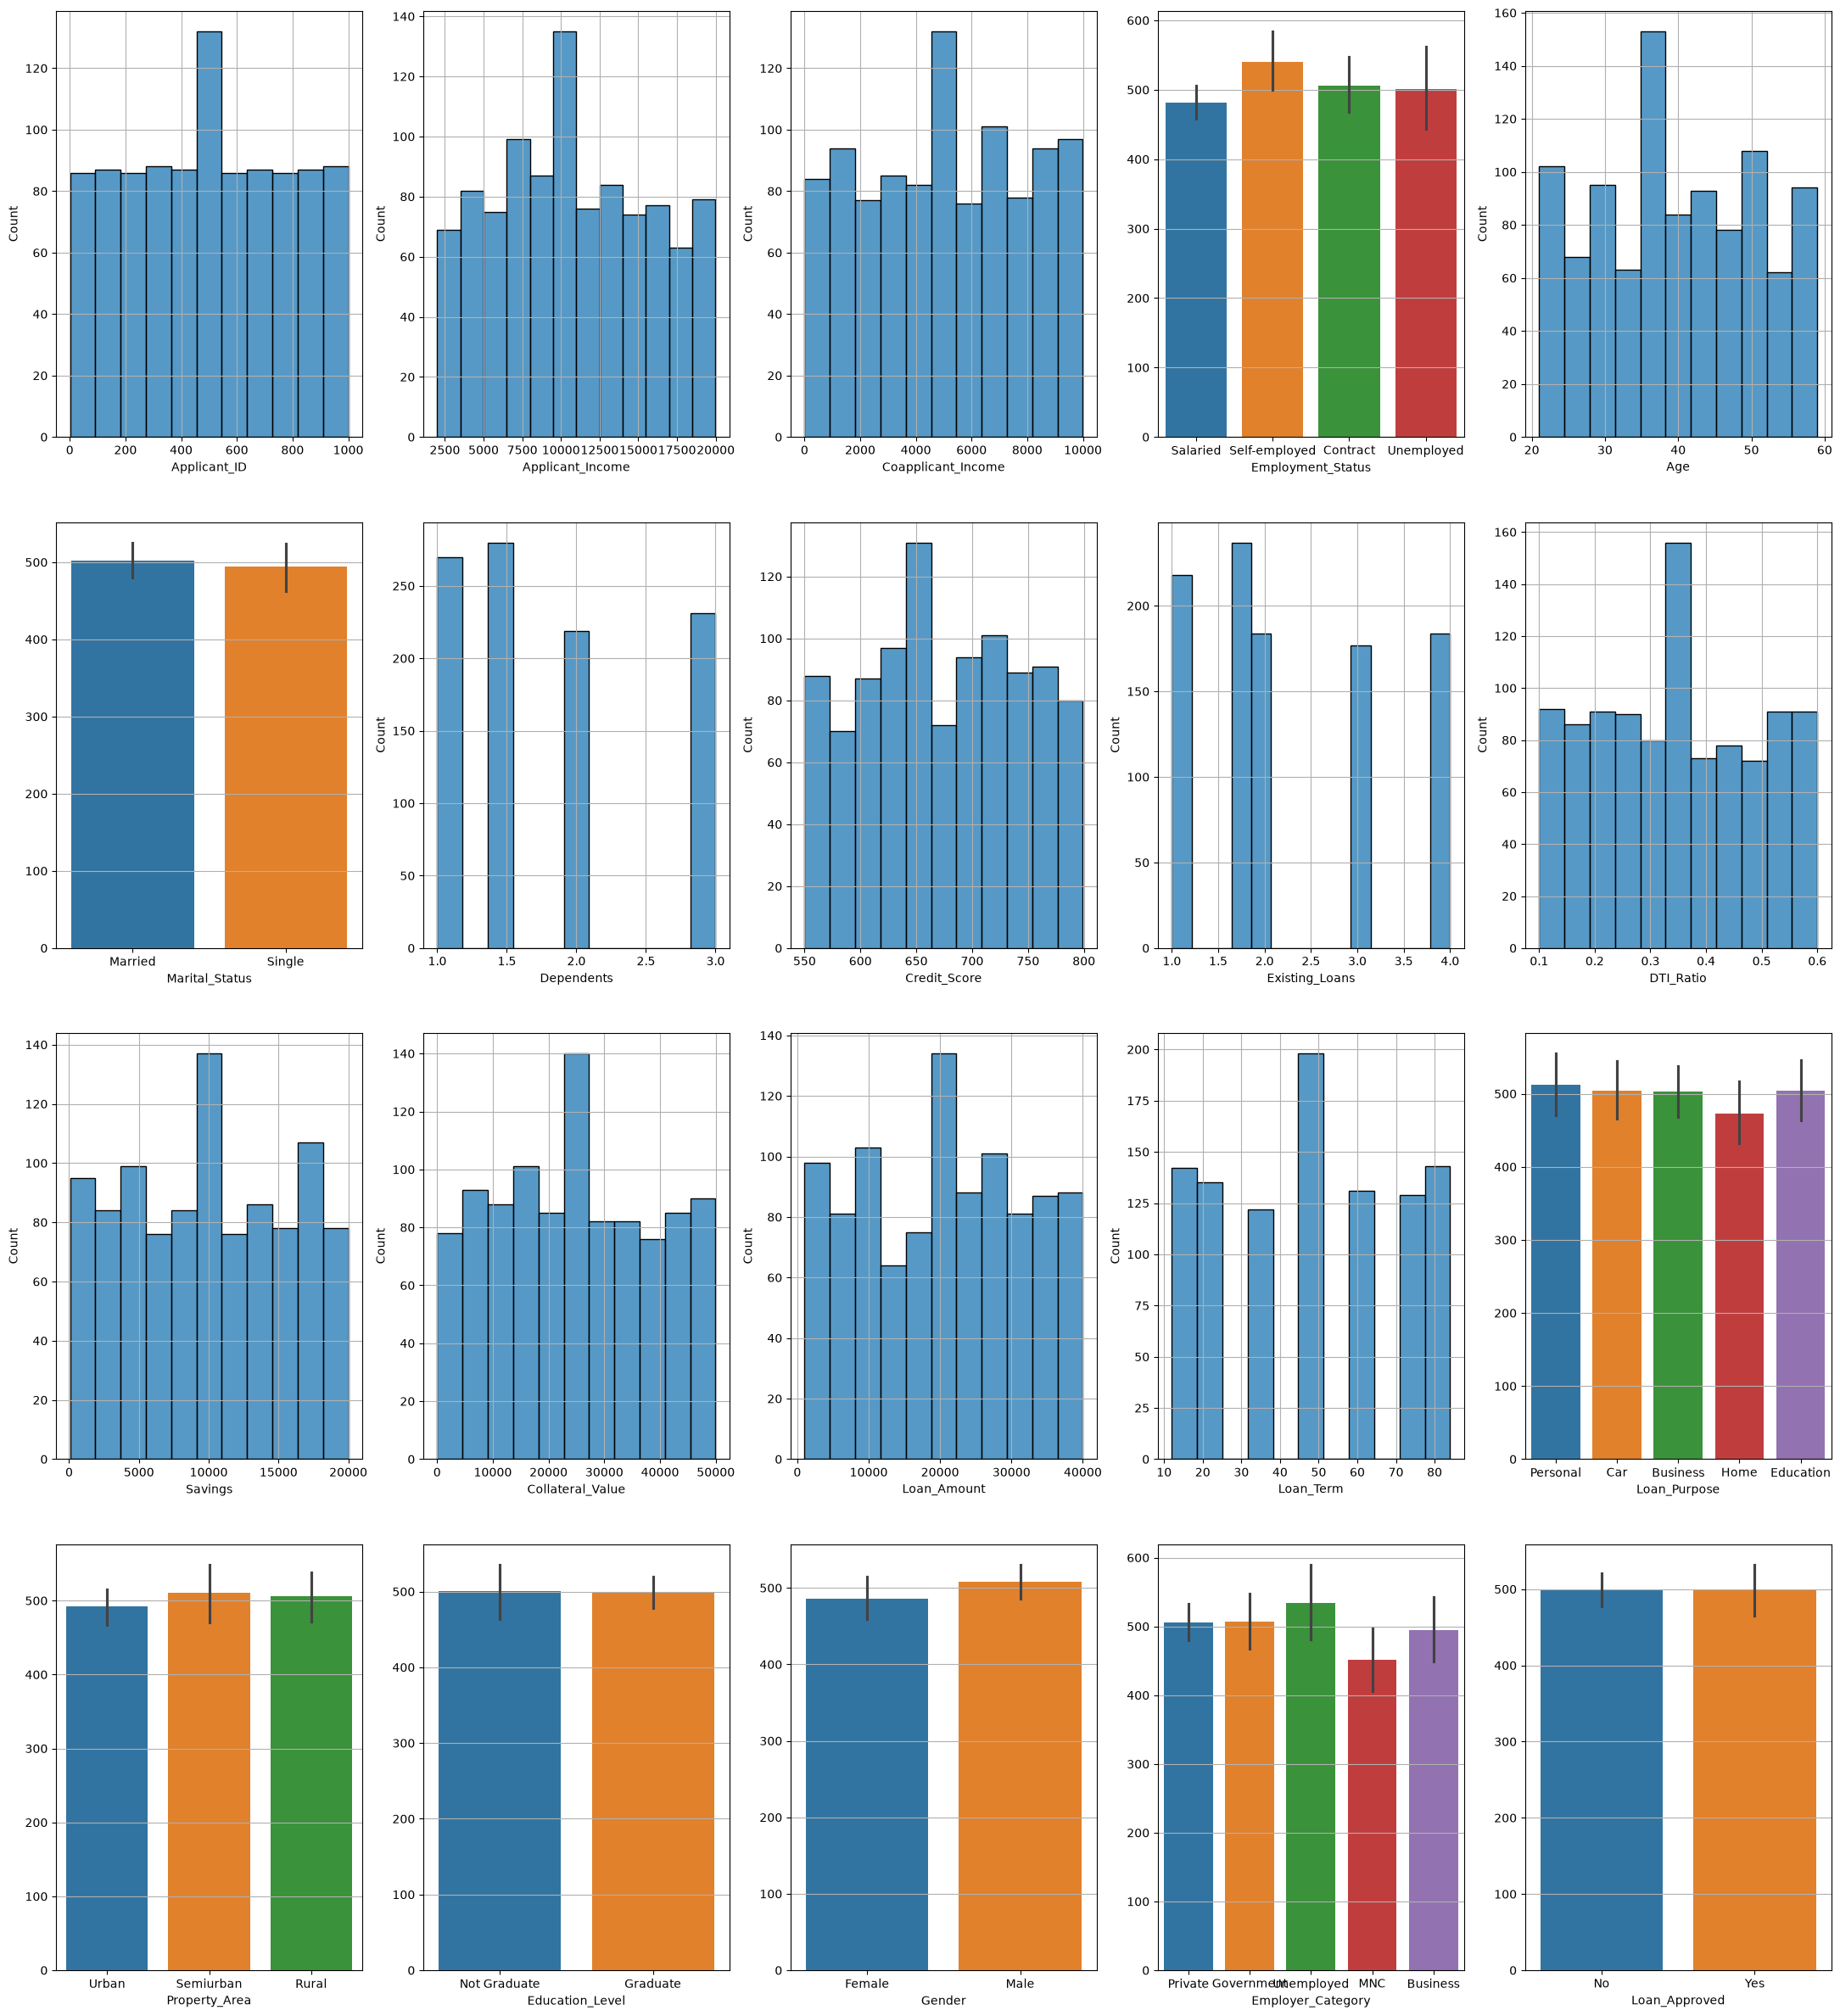

In [14]:
import matplotlib.pyplot as plt



fig, ax = plt.subplots(
    nrows=4,
    ncols=5,
    figsize=(27,30)
)
axrow=0
axcol=0
for col in data.columns:
    ax[axrow][axcol].grid()
    if("int" in str(data[col].dtype)or"float" in str(data[col].dtype)):
        sns.histplot(data=data,x=col,ax=ax[axrow][axcol])
    elif("str" in str(data[col].dtype)):
        sns.barplot(data=data,x=col,y=range(0,data.shape[0]),ax=ax[axrow][axcol],hue=col)
        
        
    if(axrow<3 and axcol==4):
            axrow+=1
    if(axcol==4):
            axcol=0
    else:
            axcol+=1
    print(f" axrow={axrow}, axcol= {axcol}")
plt.show()
fig.tight_layout()
fig.savefig("Overall Analysis.png")

# Corelation

<Figure size 640x480 with 0 Axes>

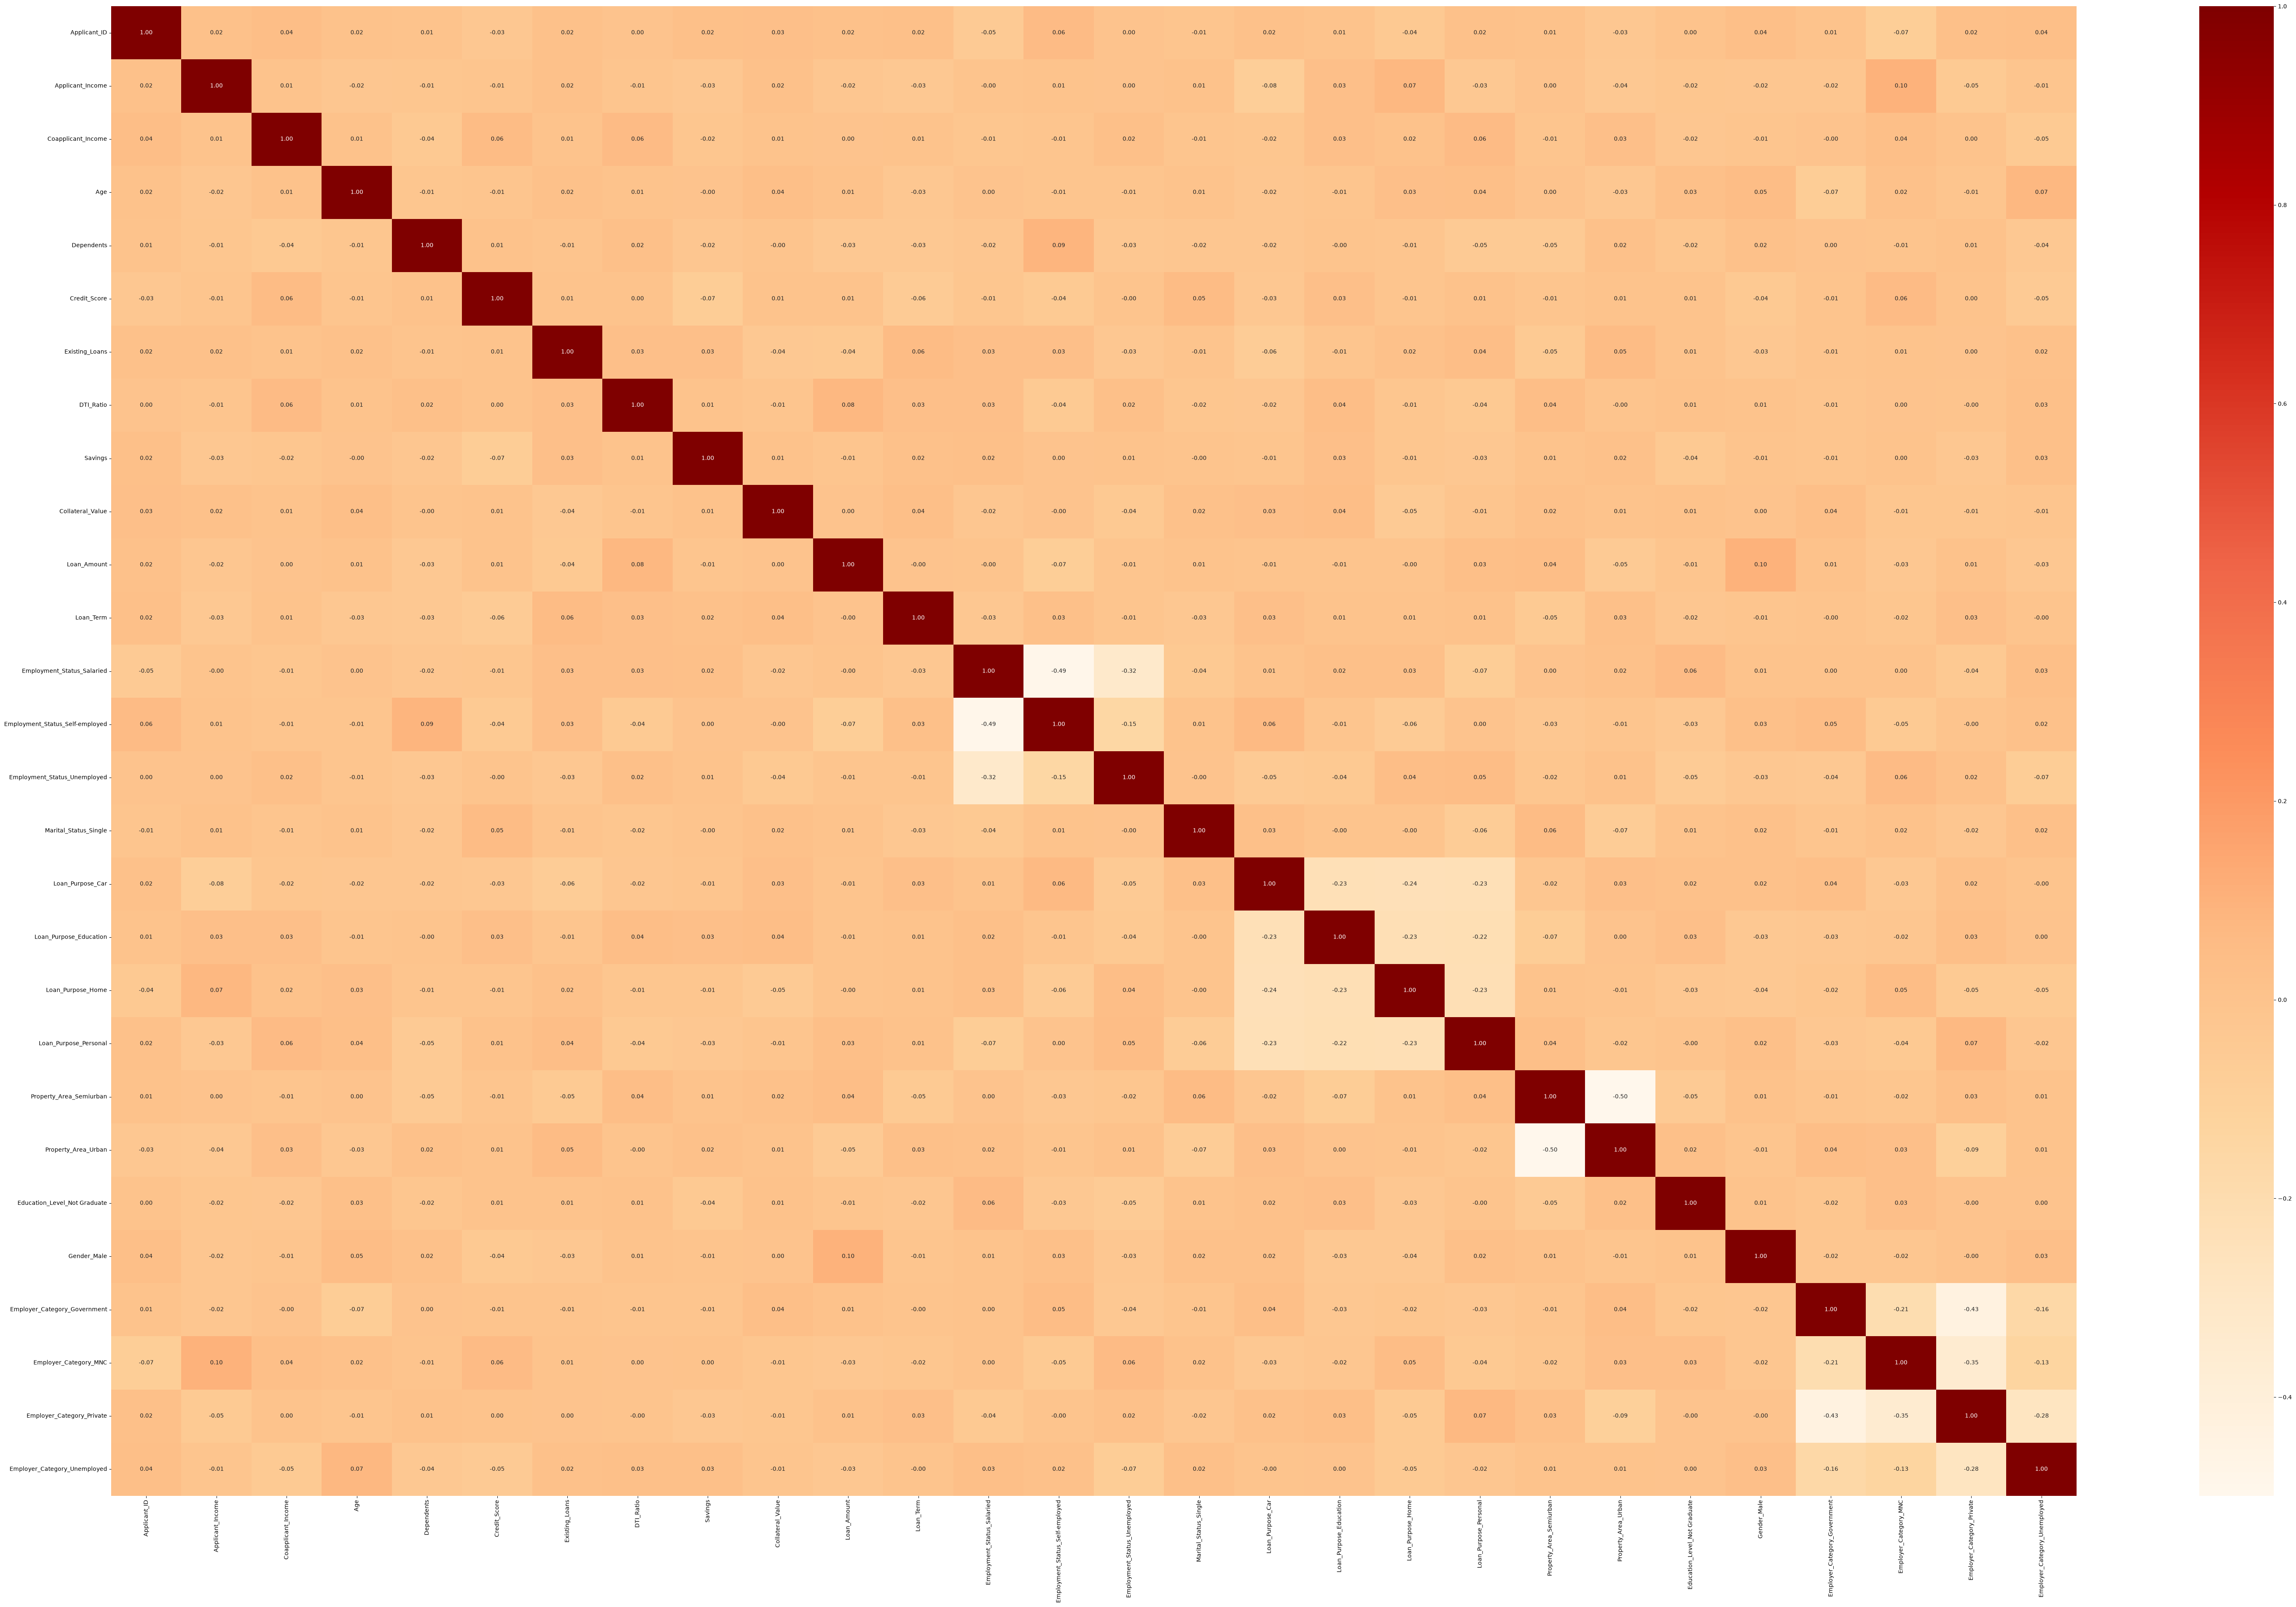

In [15]:
plt.tight_layout()


fig2, ax2 = plt.subplots( figsize=(77, 47))
sns.heatmap(data_encoded_X.corr(),cmap='OrRd',annot=True,ax=ax2,fmt='.2f')
fig2.savefig("Corelation.png")

# Useful Insights

In [16]:
data["Dependents"].head()

0    1.401
1    3.000
2    2.000
3    2.000
4    2.000
Name: Dependents, dtype: float64

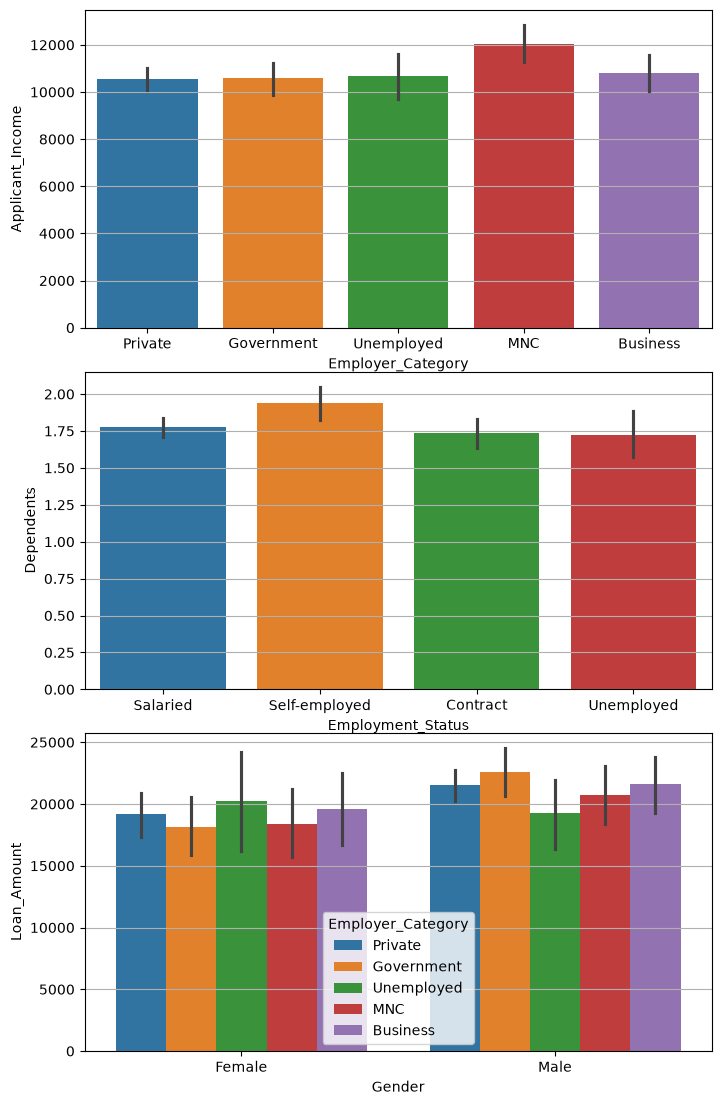

In [79]:
fig3,ax3=plt.subplots(nrows=3,ncols=1,figsize=(7,11))
fig3.tight_layout()
ax3[0].grid()


ax3[1].grid()

ax3[2].grid()
sns.barplot(data=data,y='Applicant_Income',x='Employer_Category',ax=ax3[0],hue='Employer_Category')
sns.barplot(data=data,y='Dependents',x='Employment_Status',ax=ax3[1],hue='Employment_Status')
sns.barplot(data=data,x='Gender',y='Loan_Amount',ax=ax3[2],hue='Employer_Category')
fig3.savefig("Some Relations.png")

# Logistic Regression Core

In [18]:
from sklearn.linear_model import LogisticRegression
#Train the data
model_logistic=LogisticRegression(max_iter=7923,random_state=23)
model_logistic.fit(X_train,y_train)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 7923 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=7923).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",23
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",7923
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [19]:
y_predicted_logistic=model_logistic.predict(X_test)
model_logistic.score(X_test,y_test)

0.7869565217391304

# Logistic L1

In [20]:
from sklearn.linear_model import LogisticRegression
#Train the data
model_logistic_l1=LogisticRegression(max_iter=7923,random_state=23, l1_ratio=1,solver='liblinear')
model_logistic_l1.fit(X_train,y_train)

,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",23
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",7923
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.

In [21]:
y_predicted_logistic_l1=model_logistic_l1.predict(X_test)
model_logistic_l1.score(X_test,y_test)

0.8695652173913043

# Logistic L2 and L1 Combo HyperParameter Tuning

In [22]:
from sklearn.linear_model import LogisticRegression
#Train the data
model_logistic_l1=LogisticRegression(max_iter=7923,random_state=23, l1_ratio=0)
model_logistic_l1.fit(X_train,y_train)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 7923 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=7923).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",23
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",7923
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfg

In [23]:
from sklearn.model_selection import GridSearchCV
parameters={
    "l1_ratio":[0,1,0.1,0.01,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.79,0.723,0.7239]
}
gs=GridSearchCV(model_logistic_l1,param_grid=parameters)
gs.fit(X_train,y_train)
gs_predicted=gs.predict(X_test)
gs.score(X_test,y_test)
gs.best_estimator_

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 7923 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=7923).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 7923 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=7923).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",23
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",7923
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfg

In [81]:
from sklearn.metrics import confusion_matrix,recall_score,accuracy_score,f1_score,precision_score
confusion_matrix(y_predicted_logistic_l1,y_test)
print(
    f"precision_score: {precision_score(y_predicted_logistic_l1,y_test,pos_label='No')},recall_score: {recall_score(y_predicted_logistic_l1,y_test,pos_label='No')}, accuracy_score: {accuracy_score(y_predicted_logistic_l1,y_test)}, f1_score: {f1_score(y_predicted_logistic_l1,y_test,pos_label='No')}"
)

precision_score: 0.9325153374233128,recall_score: 0.8888888888888888, accuracy_score: 0.8695652173913043, f1_score: 0.9101796407185628


# Naive Bayes

In [82]:
from sklearn.naive_bayes import GaussianNB
nb=GaussianNB()
nb.fit(X_train,y_train)
y_predict_nb=nb.predict(X_test)
f"precision_score: {precision_score(y_predict_nb,y_test,pos_label='No')},recall_score: {recall_score(y_predict_nb,y_test,pos_label='No')}, accuracy_score: {accuracy_score(y_predict_nb,y_test)}, f1_score: {f1_score(y_predict_nb,y_test,pos_label='No')}"

'precision_score: 0.8588957055214724,recall_score: 0.8187134502923976, accuracy_score: 0.7652173913043478, f1_score: 0.8383233532934131'

# Decision Trees

In [30]:
from sklearn.tree import DecisionTreeClassifier
decision_tree_classifier=DecisionTreeClassifier()

In [35]:
# Hyper Parameter Tuning
from sklearn.model_selection import GridSearchCV
parameters={
    
    'max_depth':[2,3,4,5,6,7,8,9,10,11,23],
    'min_samples_leaf':[2,3,4,5,6,7,8,9,10,11,23,79],
    'min_samples_split':[2,3,4,5,6,7,8,9,10,11,23,79],
    'ccp_alpha':[2,3,4,5,6,7,8,9,10,11,23,79]
}
gscv=GridSearchCV(decision_tree_classifier,param_grid=parameters)

In [ ]:
# Training Model
gscv.fit(X_train,y_train)

In [ ]:
y_predicted_gscv_dtc=gscv.predict(X_test)
f"precision_score: {precision_score(y_predicted_gscv_dtc,y_test,pos_label='No')},recall_score: {recall_score(y_predicted_gscv_dtc,y_test,pos_label='No')}, accuracy_score: {accuracy_score(y_predicted_gscv_dtc,y_test)}, f1_score: {f1_score(y_predicted_gscv_dtc,y_test,pos_label='No')}"

In [48]:
decision_tree_classifier=DecisionTreeClassifier(ccp_alpha=2,min_samples_leaf=2,min_samples_split=2)
decision_tree_classifier.fit(X_train,y_train)
y_predicted_dtc=decision_tree_classifier.predict(X_test)
f"precision_score: {precision_score(y_predicted_dtc,y_test,pos_label='No')},recall_score: {recall_score(y_predicted_dtc,y_test,pos_label='No')}, accuracy_score: {accuracy_score(y_predicted_dtc,y_test)}, f1_score: {f1_score(y_predicted_dtc,y_test,pos_label='No')}"

'0.7086956521739131, accuracy_score: 0.7086956521739131, f1_score: 0.8295165394402035'

[Text(0.5, 0.5, 'gini = 0.42\nsamples = 770\nvalue = [539, 231]\nclass = Yes')]

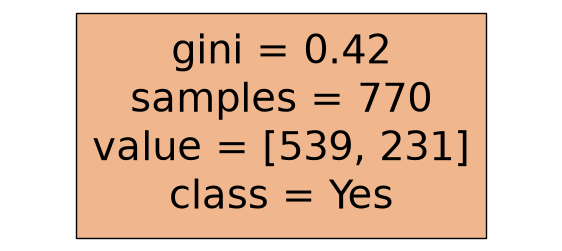

In [64]:
# Tree
from sklearn.tree import plot_tree
plt.figure(figsize=(7,3))
plot_tree(
    decision_tree_classifier,
    feature_names=X_train.columns,
    class_names=["Yes","No"],
    filled=True
)

# SVM

In [50]:
from sklearn.svm import SVC
svc_model=SVC()

In [54]:
#Tuning
from sklearn.model_selection import GridSearchCV
parameters={
    
    'C':[1,2,3,4,5,6,7,9],
    'kernel':['linear','poly','rbf']
}
gscv=GridSearchCV(svc_model,param_grid=parameters)

In [86]:
#Pre Processing
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train_scaled=sc.fit_transform(X_train)
X_test_scaled=sc.transform(X_test)

In [60]:
gscv.fit(X_train_scaled,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [1, 2, ...], 'kernel': ['linear', 'poly', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, wit

In [84]:
y_predicted_svc=gscv.predict(X_test_scaled)
f"precision_score: {precision_score(y_predicted_svc,y_test,pos_label='No')},recall_score: {recall_score(y_predicted_svc,y_test,pos_label='No')}, accuracy_score: {accuracy_score(y_predicted_svc,y_test)}, f1_score: {f1_score(y_predicted_svc,y_test,pos_label='No')}"

'precision_score: 0.9202453987730062,recall_score: 0.8875739644970414, accuracy_score: 0.8608695652173913, f1_score: 0.9036144578313253'